# Лабораторная работа №5: Сравнение статистических свойств точечных оценок математического ожидания и дисперсии

1. $N = 10^3$ выборок из $N(0, 1)$ размера $n = 10, 20, \dots, 100$. По каждой выборке:
   $c^* = \bar x = \frac1n\sum x_i$, $\;D^*_{н} = \frac1n\sum (x_i - \bar x)^2$ (неисправленная), $\;D^*_{и} = \frac{1}{n-1}\sum (x_i - \bar x)^2$ (исправленная).
   По $N$ оценкам — $M[\cdot]$ и $D[\cdot]$, сравнение с теорией, выводы о смещённости.
2. Выборочные функции распределения оценок при $n = 10$ и $n = 100$ против теоретических.

## Теория

Для выборки из $N(\mu, \sigma^2)$: $\bar x \sim N\bigl(\mu, \frac{\sigma^2}{n}\bigr)$, $\;\frac{n D^*_{н}}{\sigma^2} = \frac{(n-1) D^*_{и}}{\sigma^2} \sim \chi^2_{n-1}$, причём $\bar x$ и $D^*$ независимы. Отсюда

| оценка | $M[\cdot]$ | $D[\cdot]$ | функция распределения $F(t)$ |
|---|---|---|---|
| $c^* = \bar x$ | $\mu$ | $\dfrac{\sigma^2}{n}$ | $\Phi\Bigl(\dfrac{(t-\mu)\sqrt n}{\sigma}\Bigr)$ |
| $D^*_{н}$ | $\dfrac{n-1}{n}\sigma^2$ | $\dfrac{2(n-1)}{n^2}\sigma^4$ | $F_{\chi^2_{n-1}}\bigl(n t / \sigma^2\bigr)$ |
| $D^*_{и}$ | $\sigma^2$ | $\dfrac{2}{n-1}\sigma^4$ | $F_{\chi^2_{n-1}}\bigl((n-1) t / \sigma^2\bigr)$ |

$c^*$ и $D^*_{и}$ несмещённые, $D^*_{н}$ — смещённая (занижает дисперсию на $\sigma^2/n$), но асимптотически несмещённая.

**Погрешность моделирования.** $M[\cdot]$ и $D[\cdot]$ сами оцениваются по $N$ значениям, поэтому отличаются от теории случайно:
$\operatorname{se}(\hat M) = \sqrt{D/N}$, $\;\operatorname{se}(\hat D) \approx D\sqrt{\frac{2}{N-1} + \frac{\gamma_2}{N}}$, где $\gamma_2$ — коэффициент эксцесса оценки
($0$ для $\bar x$, $\frac{12}{n-1}$ для $\chi^2_{n-1}$). На графиках показан коридор теория $\pm 1{,}96\,\operatorname{se}$ (95 %).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
N = 10**3
NS = np.arange(10, 101, 10)
MU, SIGMA2 = 0.0, 1.0
NAMES = ['c*', 'D*н', 'D*и']

plt.rcParams['figure.dpi'] = 110
rng = np.random.default_rng(SEED)


def estimates(x):
    return {'c*': x.mean(1), 'D*н': x.var(1, ddof=0), 'D*и': x.var(1, ddof=1)}


def theory(n):
    """(M, D, эксцесс) для каждой оценки."""
    return {'c*': (MU, SIGMA2 / n, 0.0),
            'D*н': ((n - 1) / n * SIGMA2, 2 * (n - 1) / n**2 * SIGMA2**2, 12 / (n - 1)),
            'D*и': (SIGMA2, 2 / (n - 1) * SIGMA2**2, 12 / (n - 1))}


def theory_cdf(name, n, t):
    if name == 'c*':
        return stats.norm.cdf(t, MU, np.sqrt(SIGMA2 / n))
    return stats.chi2.cdf((n if name == 'D*н' else n - 1) * t / SIGMA2, n - 1)


samples = {n: estimates(rng.normal(MU, np.sqrt(SIGMA2), (N, n))) for n in NS}

## 1. Средние и дисперсии оценок

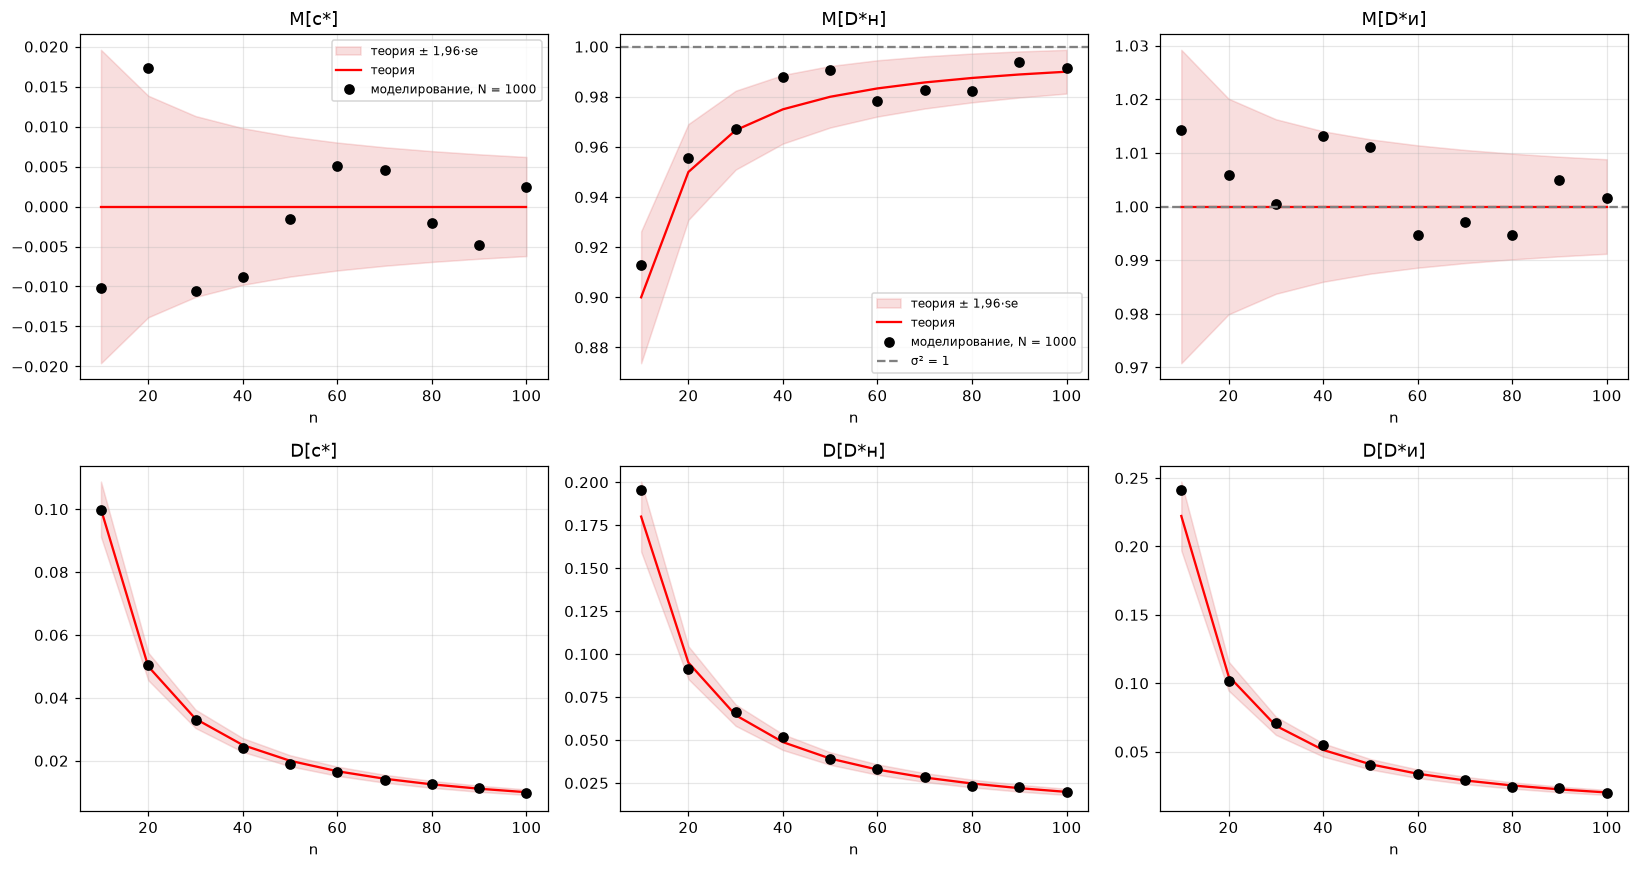

In [2]:
emp_M = {name: np.array([samples[n][name].mean() for n in NS]) for name in NAMES}
emp_D = {name: np.array([samples[n][name].var(ddof=1) for n in NS]) for name in NAMES}
th = {name: np.array([theory(n)[name] for n in NS]) for name in NAMES}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, name in enumerate(NAMES):
    M_th, D_th, g2 = th[name].T
    se_M = np.sqrt(D_th / N)
    se_D = D_th * np.sqrt(2 / (N - 1) + g2 / N)
    for row, (emp, true, se, lab) in enumerate([(emp_M[name], M_th, se_M, 'M'), (emp_D[name], D_th, se_D, 'D')]):
        ax = axes[row, col]
        ax.fill_between(NS, true - 1.96 * se, true + 1.96 * se, color='tab:red', alpha=0.15, label='теория ± 1,96·se')
        ax.plot(NS, true, 'r-', label='теория')
        ax.plot(NS, emp, 'ko', label=f'моделирование, N = {N}')
        ax.set(title=f'{lab}[{name}]', xlabel='n')
        ax.grid(alpha=0.3)
    if name != 'c*':
        axes[0, col].axhline(SIGMA2, color='gray', ls='--', label='σ² = 1')
axes[0, 0].legend(fontsize=8)
axes[0, 1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Проверка смещённости.** Гипотеза $H_0: M[\theta^*] = \theta$ ($\theta = \mu$ для $c^*$, $\sigma^2$ для $D^*$), статистика
$z = \dfrac{\hat M[\theta^*] - \theta}{\sqrt{\hat D[\theta^*] / N}} \approx N(0, 1)$ при $H_0$.

In [3]:
print(f'{"n":>4} | {"смещение (теория / модель)":^42} | {"z (p-value)":^48}')
print(f'{"":>4} | ' + ''.join(f'{name:>14}' for name in NAMES) + ' | ' + ''.join(f'{name:>16}' for name in NAMES))
for i, n in enumerate(NS):
    bias, zs = [], []
    for name in NAMES:
        target = MU if name == 'c*' else SIGMA2
        b = emp_M[name][i] - target
        z = b / np.sqrt(emp_D[name][i] / N)
        bias.append(f'{th[name][i, 0] - target:+6.3f}/{b:+6.3f}')
        zs.append(f'{z:+6.2f} ({2 * stats.norm.sf(abs(z)):.3f})')
    print(f'{n:>4} | ' + ''.join(f'{s:>14}' for s in bias) + ' | ' + ''.join(f'{s:>16}' for s in zs))

   n |         смещение (теория / модель)         |                   z (p-value)                   
     |             c*           D*н           D*и |               c*             D*н             D*и
  10 |  +0.000/-0.010 -0.100/-0.087 +0.000/+0.014 |    -1.03 (0.305)   -6.23 (0.000)   +0.92 (0.358)
  20 |  +0.000/+0.017 -0.050/-0.044 +0.000/+0.006 |    +2.45 (0.014)   -4.64 (0.000)   +0.58 (0.559)
  30 |  +0.000/-0.011 -0.033/-0.033 +0.000/+0.001 |    -1.84 (0.066)   -4.03 (0.000)   +0.06 (0.950)
  40 |  +0.000/-0.009 -0.025/-0.012 +0.000/+0.013 |    -1.78 (0.074)   -1.69 (0.091)   +1.78 (0.075)
  50 |  +0.000/-0.002 -0.020/-0.009 +0.000/+0.011 |    -0.36 (0.718)   -1.47 (0.143)   +1.75 (0.081)
  60 |  +0.000/+0.005 -0.017/-0.022 +0.000/-0.005 |    +1.25 (0.210)   -3.80 (0.000)   -0.90 (0.369)
  70 |  +0.000/+0.005 -0.014/-0.017 +0.000/-0.003 |    +1.23 (0.220)   -3.23 (0.001)   -0.55 (0.584)
  80 |  +0.000/-0.002 -0.012/-0.018 +0.000/-0.005 |    -0.57 (0.570)   -3.66 (0.000)   -1.0

### Выводы по п. 1

- **Дисперсии оценок** $D[c^*]$, $D[D^*_{н}]$, $D[D^*_{и}]$ совпадают с теоретическими $\sigma^2/n$, $2(n-1)\sigma^4/n^2$, $2\sigma^4/(n-1)$ и убывают как $1/n$ — все три оценки состоятельны.
- **$c^*$ и $D^*_{и}$ несмещённые:** $\hat M$ колеблется вокруг $\mu = 0$ и $\sigma^2 = 1$ в пределах 95%-го коридора погрешности моделирования; $z$-статистики в основном $|z| < 2$. Единичный выход ($c^*$ при $n = 20$, $p \approx 0{,}01$) ожидаем: при 30 проверках на уровне 5 % случайно отвергается в среднем 1–2 гипотезы.
- **$D^*_{н}$ смещённая:** $\hat M[D^*_{н}]$ идёт по кривой $\frac{n-1}{n}\sigma^2$, а не по $\sigma^2$. При малых $n$ смещение $-\sigma^2/n$ значимо ($|z| = 4$–$6$ при $n \le 30$).
- При $n \gtrsim 40$ смещение $-\sigma^2/n \le 0{,}025$ сравнимо с погрешностью моделирования ($\operatorname{se} \approx 0{,}005$–$0{,}007$), поэтому при $N = 10^3$ оно обнаруживается не всегда (при $n = 40, 50, 90, 100$ $p > 0{,}05$). Это не означает несмещённости: так проявляется **асимптотическая** несмещённость $D^*_{н}$ и ограниченная мощность теста. Теоретическая кривая при этом всё равно лежит внутри коридора.
- $D[D^*_{н}] < D[D^*_{и}]$ (множитель $\left(\frac{n-1}{n}\right)^2$): неисправленная оценка немного устойчивее, но за счёт систематического занижения.

## 2. Выборочные функции распределения оценок

Для $n = 10$ и $n = 100$ строим ЭФР по $N$ значениям каждой оценки и накладываем теоретическую ФР из таблицы.
Согласие проверяем критерием Колмогорова–Смирнова.

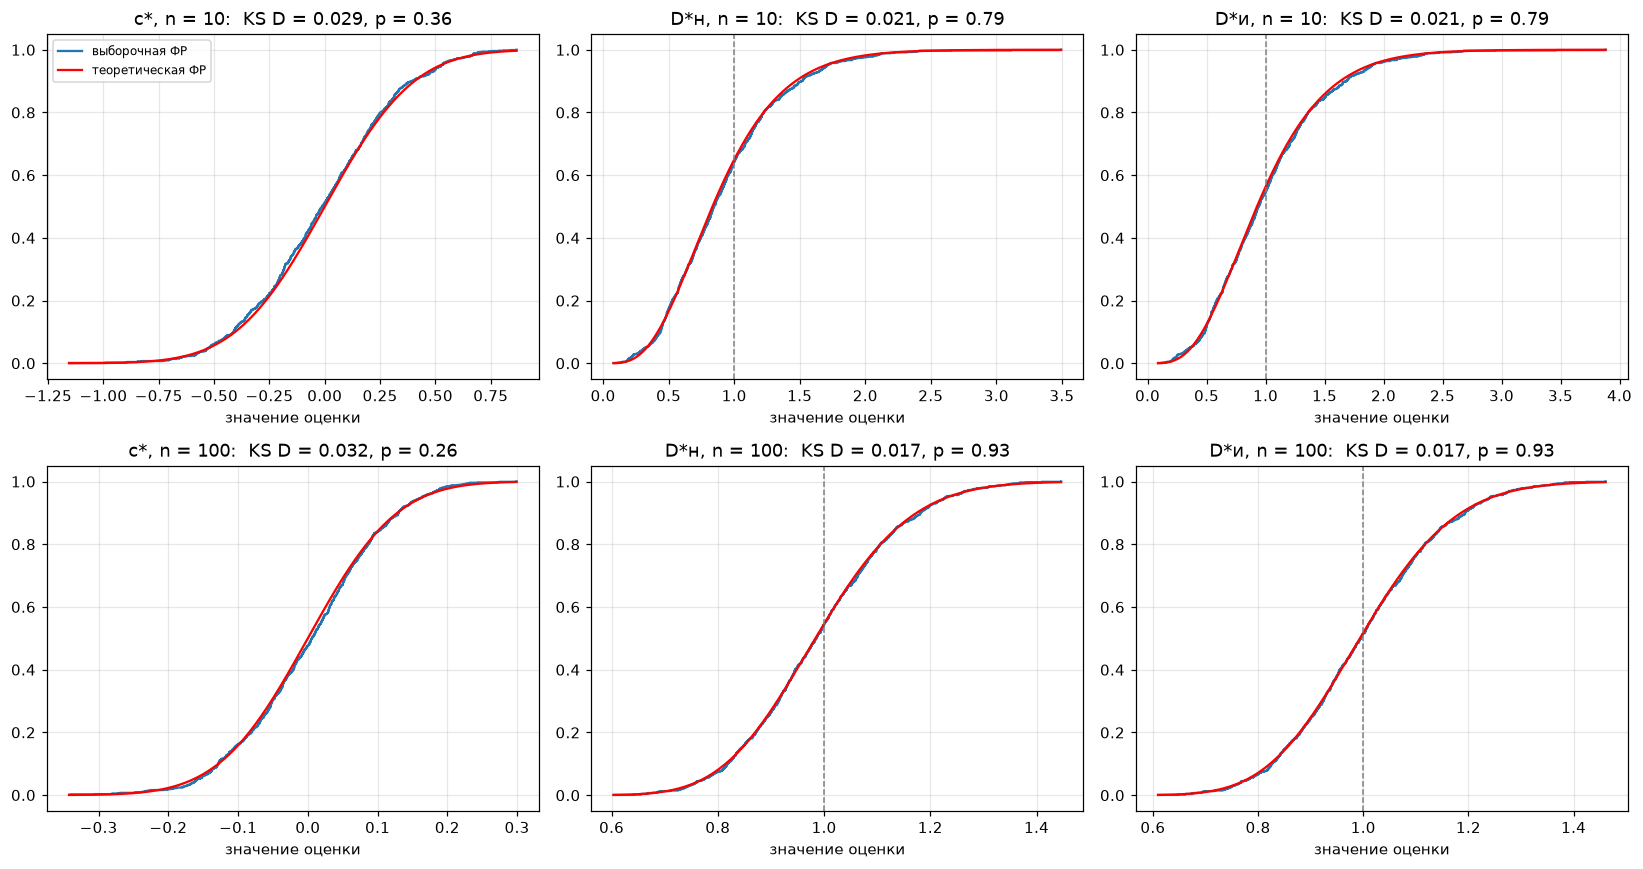

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, n in enumerate([10, 100]):
    for col, name in enumerate(NAMES):
        v = np.sort(samples[n][name])
        t = np.linspace(v[0], v[-1], 400)
        ks = stats.kstest(v, lambda s: theory_cdf(name, n, s))
        ax = axes[row, col]
        ax.step(v, np.arange(1, N + 1) / N, where='post', label='выборочная ФР')
        ax.plot(t, theory_cdf(name, n, t), 'r-', label='теоретическая ФР')
        if name != 'c*':
            ax.axvline(SIGMA2, color='gray', ls='--', lw=1)
        ax.set(title=f'{name}, n = {n}:  KS D = {ks.statistic:.3f}, p = {ks.pvalue:.2f}', xlabel='значение оценки')
        ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Выводы по п. 2

- Выборочные ФР всех оценок практически совпадают с теоретическими; критерий Колмогорова–Смирнова не отвергает согласие ни в одном случае ($p > 0{,}2$).
- $c^*$ распределена нормально при любом $n$; с ростом $n$ от 10 до 100 разброс сужается в $\sqrt{10} \approx 3{,}2$ раза.
- Распределения $D^*_{н}$ и $D^*_{и}$ — масштабированный $\chi^2_{n-1}$. При $n = 10$ оно заметно **асимметрично** (коэффициент асимметрии $\approx 0{,}94$): медиана ниже $\sigma^2$, и даже несмещённая $D^*_{и}$ занижает дисперсию с вероятностью $P(D^*_{и} < \sigma^2) \approx 0{,}56$, а смещённая $D^*_{н}$ — с вероятностью $0{,}65$ (ФР $D^*_{н}$ сдвинута влево).
- При $n = 100$ асимметрия мала ($\approx 0{,}28$), распределения обеих оценок близки к нормальному и почти совпадают: $P(D^*_{и} < \sigma^2) \approx 0{,}52$, $P(D^*_{н} < \sigma^2) \approx 0{,}55$. Разница между исправленной и неисправленной оценками с ростом $n$ исчезает.